# U.S. additional algorithm comparison

Compare HGB, XGBoost, native-categorical CatBoost and LightGBM using the 26,945 official U.S. training campaigns. Preserve v1, city v2, official datasets and existing notebook outputs. No reserved labels, application changes or automatic model saving.

Feature sets: conservative; conservative plus city frequency; reward count only; and a separate reward ladder with count, minimum/maximum/median log amounts and log amount relative to goal. Rewards are exploratory. No title, timing, updates, pledges, backers or activity features.

In [1]:
from pathlib import Path
import sys, time, json, hashlib, platform
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'utils/us_modeling.py').is_file())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import sklearn, joblib, xgboost, catboost, lightgbm
import matplotlib.pyplot as plt
from utils.us_modeling import load_us_training_data
from utils.us_algorithm_comparison import compare_algorithms, FEATURE_SETS, parameter_options, ALGORITHMS

OUT = ROOT / 'docs/additional_model_results'
OUT.mkdir(exist_ok=True)
X, y, ids = load_us_training_data(ROOT)
# Whitelist sources before comparison, even though the builders ignore others.
X = X[['goal', 'duration', 'category', 'subcategory', 'location', 'reward levels']].copy()
assert len(X) == 26945 and ids.is_unique
protected_paths = [ROOT / 'models' / (name + suffix)
                   for name in ['us_primary_model_v1', 'us_candidate_v2']
                   for suffix in ['.joblib', '.metadata.json']]
protected = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in protected_paths}
environment = dict(python=platform.python_version(), sklearn=sklearn.__version__, numpy=np.__version__,
                   pandas=pd.__version__, scipy=__import__('scipy').__version__, joblib=joblib.__version__,
                   xgboost=xgboost.__version__, catboost=catboost.__version__, lightgbm=lightgbm.__version__)
manifest = dict(environment=environment, training_rows=len(X),
                ordered_training_ids_sha256=hashlib.sha256('\n'.join(ids.astype(str)).encode()).hexdigest(),
                protected_artifacts=protected,
                feature_sets=FEATURE_SETS, settings={a: parameter_options(a) for a in ALGORITHMS})
(OUT / 'manifest.txt').write_text(json.dumps(manifest, indent=2) + '\n')
print(environment)
print('Official U.S. training rows:', len(X))

{'python': '3.12.3', 'sklearn': '1.9.1', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'joblib': '1.6.0', 'xgboost': '3.4.1', 'catboost': '1.2.10', 'lightgbm': '4.7.0'}
Official U.S. training rows: 26945


## Validation plan

Use the existing three shuffled stratified outer folds at seed 20261027. Two inner folds use seed 100 + outer-fold number. HGB retains its frozen settings and .5 threshold. Each additional algorithm has two prespecified settings; inner pooled ROC-AUC chooses settings. From .45/.50/.55, choose the most accurate inner threshold whose failure recall loses no more than .01 relative to the corresponding inner HGB at .5. Fall back to .5 if none qualifies, and do not infer eligibility from that fallback.

Report fixed-.5 results alongside inner-threshold results. A separate inner family-selection procedure considers only candidates gaining at least .003 accuracy, losing at most .002 AUC and .01 failure recall; otherwise it retains HGB. No choices use outer validation labels. No early stopping uses outer validation; iteration counts are fixed.

HGB/XGBoost/LightGBM share the same engineered values, fold-fitted medians, imputation/scaling and cross-fitted target encoding. CatBoost receives the same numeric definitions and raw category/subcategory/state strings, with missing-category markers and native Ordered boosting. It does not also receive external target encodings or one-hot features. This compares complete pipelines; it does not isolate algorithms under identical encodings.

All fits use one numerical thread and seed 42. Earlier tuning and repeated use of these outer folds still create selection bias. Nested selection of this small new grid does not replay the original search or prove prospective superiority. Reward provenance remains unresolved regardless of scores.

In [2]:
started = time.perf_counter()
summary, folds, inner, paired = compare_algorithms(X, y)
elapsed = time.perf_counter() - started
summary.to_csv(OUT / 'summary.csv', index=False)
folds.to_csv(OUT / 'outer_folds.csv', index=False)
inner.to_csv(OUT / 'inner_options.csv', index=False)
paired.to_csv(OUT / 'paired_folds.csv', index=False)
(OUT / 'runtime.txt').write_text(f'Total comparison seconds: {elapsed:.3f}\n')
columns = ['feature_set', 'algorithm', 'accuracy', 'roc_auc', 'success_f1', 'failure_f1', 'failure_recall', 'brier', 'fit_seconds', 'predict_seconds']
display(summary[summary.policy.eq('fixed_0.5')][columns].round(4))
print('Total comparison seconds:', round(elapsed, 2))

conservative: outer fold 1/3 complete; inner selected XGBoost
conservative: outer fold 2/3 complete; inner selected HGB
conservative: outer fold 3/3 complete; inner selected HGB
city: outer fold 1/3 complete; inner selected HGB
city: outer fold 2/3 complete; inner selected CatBoost
city: outer fold 3/3 complete; inner selected HGB
reward_count_exploratory: outer fold 1/3 complete; inner selected HGB
reward_count_exploratory: outer fold 2/3 complete; inner selected HGB
reward_count_exploratory: outer fold 3/3 complete; inner selected HGB
reward_ladder_exploratory: outer fold 1/3 complete; inner selected HGB
reward_ladder_exploratory: outer fold 2/3 complete; inner selected HGB
reward_ladder_exploratory: outer fold 3/3 complete; inner selected HGB


,feature_set,algorithm,accuracy,roc_auc,success_f1,failure_f1,failure_recall,brier,fit_seconds,predict_seconds
0,conservative,HGB,0.6693,0.7239,0.7158,0.6047,0.5572,0.2096,0.3525,0.0603
2,conservative,XGBoost,0.6711,0.7244,0.7182,0.6052,0.5554,0.2094,0.2354,0.0364
4,conservative,CatBoost,0.6713,0.7240,0.7212,0.5996,0.5423,0.2107,7.3523,0.0176
6,conservative,LightGBM,0.6705,0.7235,0.7167,0.6062,0.5588,0.2098,0.3484,0.1179
9,city,HGB,0.6770,0.7323,0.7212,0.6163,0.5716,0.2068,0.3850,0.0782
11,city,XGBoost,0.6767,0.7330,0.7215,0.6146,0.5681,0.2065,0.2691,0.0266
13,city,CatBoost,0.6770,0.7328,0.7237,0.6112,0.5595,0.2075,7.6183,0.0204
15,city,LightGBM,0.6793,0.7326,0.7226,0.6201,0.5767,0.2067,0.3874,0.1248
18,reward_count_exploratory,HGB,0.7015,0.7597,0.7440,0.6423,0.5904,0.1959,0.7080,0.2261
20,reward_count_exploratory,XGBoost,0.6998,0.7605,0.7433,0.6386,0.5844,0.1957,0.5356,0.1614


Total comparison seconds: 467.08


In [3]:
display(summary[summary.policy.eq('inner_threshold')][columns].round(4))
display(folds[folds.policy.eq('inner_threshold')][['feature_set', 'fold', 'algorithm', 'threshold', 'parameters']])
# Both class precisions, recalls and all confusion counts remain in summary.csv.
display(summary[['feature_set', 'algorithm', 'policy', 'tn', 'fp', 'fn', 'tp']])

,feature_set,algorithm,accuracy,roc_auc,success_f1,failure_f1,failure_recall,brier,fit_seconds,predict_seconds
1,conservative,HGB,0.6693,0.7239,0.7158,0.6047,0.5572,0.2096,0.3525,0.0603
3,conservative,XGBoost,0.6711,0.7244,0.7182,0.6052,0.5554,0.2094,0.2354,0.0364
5,conservative,CatBoost,0.6662,0.7240,0.6904,0.6380,0.6480,0.2107,7.3523,0.0176
7,conservative,LightGBM,0.6705,0.7235,0.7167,0.6062,0.5588,0.2098,0.3484,0.1179
8,conservative,inner_family_selection,0.6697,0.7243,0.7162,0.6049,0.5572,0.2094,0.3349,0.0490
10,city,HGB,0.6770,0.7323,0.7212,0.6163,0.5716,0.2068,0.3850,0.0782
12,city,XGBoost,0.6767,0.7330,0.7215,0.6146,0.5681,0.2065,0.2691,0.0266
14,city,CatBoost,0.6759,0.7328,0.7150,0.6244,0.5935,0.2075,7.6183,0.0204
16,city,LightGBM,0.6793,0.7326,0.7226,0.6201,0.5767,0.2067,0.3874,0.1248
17,city,inner_family_selection,0.6769,0.7317,0.7226,0.6132,0.5642,0.2073,2.1994,0.0637


,feature_set,fold,algorithm,threshold,parameters
1,conservative,1,HGB,0.50,{}
3,conservative,1,XGBoost,0.50,"{'max_depth': 3, 'n_estimators': 250}"
5,conservative,1,CatBoost,0.55,"{'depth': 4, 'iterations': 250}"
7,conservative,1,LightGBM,0.50,"{'num_leaves': 15, 'n_estimators': 250}"
8,conservative,1,inner_family_selection,0.50,NaN
10,conservative,2,HGB,0.50,{}
12,conservative,2,XGBoost,0.50,"{'max_depth': 3, 'n_estimators': 250}"
14,conservative,2,CatBoost,0.55,"{'depth': 4, 'iterations': 250}"
16,conservative,2,LightGBM,0.50,"{'num_leaves': 15, 'n_estimators': 250}"
17,conservative,2,inner_family_selection,0.50,NaN


,feature_set,algorithm,policy,tn,fp,fn,tp
0,conservative,HGB,fixed_0.5,6814,5415,3495,11221
1,conservative,HGB,inner_threshold,6814,5415,3495,11221
2,conservative,XGBoost,fixed_0.5,6792,5437,3425,11291
3,conservative,XGBoost,inner_threshold,6792,5437,3425,11291
4,conservative,CatBoost,fixed_0.5,6632,5597,3261,11455
5,conservative,CatBoost,inner_threshold,7925,4304,4690,10026
6,conservative,LightGBM,fixed_0.5,6834,5395,3484,11232
7,conservative,LightGBM,inner_threshold,6834,5395,3484,11232
8,conservative,inner_family_selection,inner_threshold,6814,5415,3486,11230
9,city,HGB,fixed_0.5,6990,5239,3463,11253


,feature_set,fold,algorithm,accuracy_delta,roc_auc_delta,failure_recall_delta
3,conservative,1,XGBoost,0.0010,0.0009,0.0000
5,conservative,1,CatBoost,-0.0021,0.0003,0.0858
7,conservative,1,LightGBM,-0.0026,-0.0017,-0.0029
8,conservative,1,inner_family_selection,0.0010,0.0009,0.0000
12,conservative,2,XGBoost,0.0043,-0.0007,0.0005
14,conservative,2,CatBoost,-0.0028,0.0006,0.0952
16,conservative,2,LightGBM,0.0032,-0.0004,0.0088
17,conservative,2,inner_family_selection,0.0000,0.0000,0.0000
21,conservative,3,XGBoost,0.0000,0.0011,-0.0059
23,conservative,3,CatBoost,-0.0045,-0.0005,0.0915


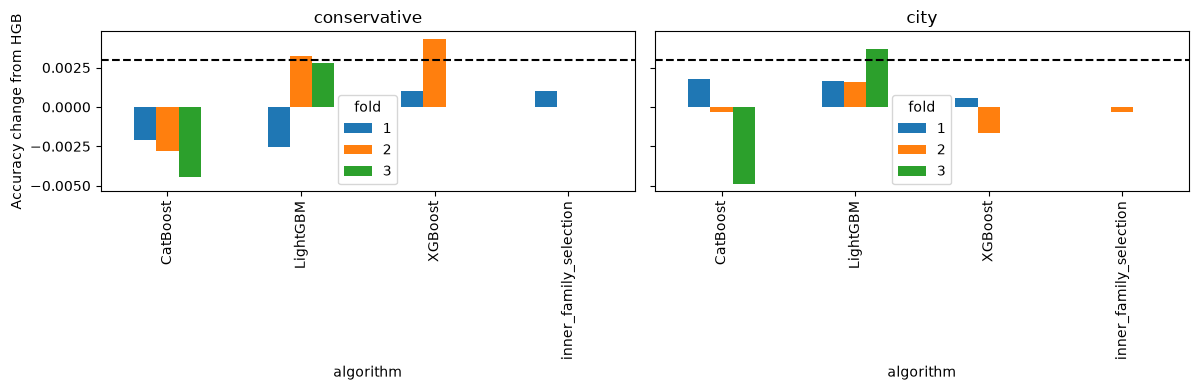

In [4]:
comparison = paired[paired.policy.eq('inner_threshold') & ~paired.algorithm.eq('HGB')]
display(comparison[['feature_set', 'fold', 'algorithm', 'accuracy_delta', 'roc_auc_delta', 'failure_recall_delta']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, feature_set in zip(axes, ['conservative', 'city']):
    table = comparison[comparison.feature_set.eq(feature_set)].pivot(index='algorithm', columns='fold', values='accuracy_delta')
    table.plot.bar(ax=ax)
    ax.axhline(.003, color='black', linestyle='--')
    ax.set_title(feature_set)
    ax.set_ylabel('Accuracy change from HGB')
plt.tight_layout()
plt.savefig(OUT / 'paired_accuracy.png', dpi=140)
plt.show()

## Eligibility and decisions

Review paired accuracy, AUC and failure recall before recommending any candidate. The .003 accuracy floor is only one guardrail; require improvement in at least two outer folds and inspect calibration, runtime and input coverage too. Candidate selection from outer summaries adds optimism and is not an independent test. This notebook does not serialize a model or modify the dashboard.

Reward count and amount summaries are plausible planned inputs, but 2012 first-party sources document tiers added during campaigns. Our scrape has no initial-tier revision history, so both reward sets stay exploratory. See `docs/additional_model_research.md` for source links and recommendation-method feasibility.

Additional algorithms cannot establish comparable global funding units or verified location coverage. Keep global unavailable pending its own conservative training-only validation, currency/coverage policy and artifact/interface contract. Global includes U.S.

Results: conservative XGBoost/CatBoost/LightGBM at .5 reach 67.11%/67.13%/67.05%, versus HGB 66.93%. City LightGBM reaches 67.94%, only .00230 above HGB city, below the .003 floor. No new candidate is saved. CatBoost inner thresholds increase failure recall with reduced accuracy. HGB reward ladder reaches 71.17% but remains exploratory. Retain v1 primary and the separate city HGB candidate.

In [5]:
for path, digest in protected.items():
    assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest
print('v1 and city v2 artifacts/metadata unchanged. No reserved labels read or model saved.')

v1 and city v2 artifacts/metadata unchanged. No reserved labels read or model saved.
